# Ejecución de pruebas: Simulación de la Red Social Instagram (Usuarios Estándar y VIP)

Se utilizan **las cuatro cuentas registradas en `main.py`**. Todas comienzan como usuarios estándar y, durante la prueba, Sebastián pasa a VIP para demostrar sus beneficios. No se modifica el código original del proyecto.

## 1. Cuentas registradas en el sistema

In [1]:
from Clase_usuario import Usuario
from usuario_vip import UsuarioVip
from publicacion import Publicacion
%matplotlib inline
import matplotlib.pyplot as plt

valeria = Usuario("valedies_1", "Valeria Guadalupe Diestra Buelot", "valediestra@gmail.com")
gustavo = Usuario("gbustillos_2", "Gustavo Enrique Bustillos Semeler", "gbustillos@gmail.com")
stayci = Usuario("stayci_3", "Stayci Marisol Ovalle Muñoz", "sovalle@gmail.com")
sebastian = Usuario("sebastian_4", "Sebastián Mauricio Díaz Pasache", "sdiaz@gmail.com")

usuarios = [valeria, gustavo, stayci, sebastian]
print("Cuentas:", [u.obtener_nombre_usuario() for u in usuarios])

Cuentas: ['valedies_1', 'gbustillos_2', 'stayci_3', 'sebastian_4']


## 2. Seguidores, historias y listas de público

Se comprueba el seguimiento, dejar de seguir, ver historias y el límite de tres listas para usuarios estándar.

In [2]:
assert valeria.seguir(gustavo)
assert valeria.seguir(stayci)
assert stayci.seguir(gustavo)
assert sebastian.seguir(stayci)
assert gustavo.seguir(sebastian)
assert gustavo.cantidad_seguidores() == 2

assert valeria.dejar_de_seguir(stayci)
assert valeria.seguir(stayci)

gustavo.publicar_historia("Historia de Gustavo")
assert valeria.ver_historia(gustavo)
assert valeria in gustavo.obtener_vistas_por()

for nombre in ["Amigos", "Familia", "Trabajo"]:
    assert valeria.crear_lista_publico(nombre)
assert not valeria.crear_lista_publico("Extra")

print("Seguidores de Gustavo:", gustavo.cantidad_seguidores())
print("Historias de Gustavo:", gustavo.obtener_historias())
print("Listas de Valeria:", valeria.obtener_listas_publico())
print("Prueba de usuarios estándar: CORRECTA")

Seguidores de Gustavo: 2
Historias de Gustavo: ['Historia de Gustavo']
Listas de Valeria: ['Amigos', 'Familia', 'Trabajo']
Prueba de usuarios estándar: CORRECTA


## 3. Publicaciones, likes, comentarios y compartidos

In [3]:
publicacion = Publicacion(gustavo, "Foto del equipo")
gustavo.obtener_publicaciones().append(publicacion)
gustavo.obtener_publicaciones().append(Publicacion(gustavo, ""))
valeria.obtener_publicaciones().append(Publicacion(valeria, "Foto de viaje"))
stayci.obtener_publicaciones().append(Publicacion(stayci, "Foto del evento"))

assert publicacion.dar_like(valeria)
assert publicacion.comentar(stayci, "¡Buena foto!")
assert publicacion.compartir() == 1
assert publicacion.cantidad_interacciones() == 3
assert publicacion.quitar_like(valeria)

print("Publicación:", publicacion)
print("Comentarios:", publicacion.obtener_comentarios())
print("Publicación sin texto: permitida")
print("Prueba de publicaciones: CORRECTA")

Publicación: @gbustillos_2: Foto del equipo | Likes: 0 | Comentarios: 1 | Compartidos: 1
Comentarios: ['@stayci_3: ¡Buena foto!']
Publicación sin texto: permitida
Prueba de publicaciones: CORRECTA


## 4. Funcionalidades de UsuarioVip

Se convierte la cuenta existente de Sebastián a VIP, como en la opción 5 de `main.py`. Se prueban la visualización discreta, Spotlight, los supercorazones, las listas y las publicaciones fijadas.

In [4]:
# Convertir a Sebastián en VIP sin cambiar el objeto que siguen los demás
seguidores_antes = sebastian.cantidad_seguidores()
sebastian.__class__ = UsuarioVip
sebastian._insignia = "💎 Instagram Plus"
sebastian._historias_spotlight = []
sebastian._supercorazones_enviados = []
assert sebastian.establecer_estado_plus(True)
assert sebastian.cantidad_seguidores() == seguidores_antes
assert gustavo.dejar_de_seguir(sebastian)
assert gustavo.seguir(sebastian)

assert sebastian.duracion_historia() == 48
assert sebastian.cambiar_icono("Oscuro")
assert sebastian.cambiar_tipografia("Cursiva")

sebastian.publicar_historia("Historia VIP de Sebastián")
assert sebastian.destacar_historia("Historia VIP de Sebastián")
assert sebastian.ver_historia(gustavo)
assert sebastian not in gustavo.obtener_vistas_por()  # Vista discreta
assert sebastian.enviar_supercorazon(gustavo, "Historia de Gustavo")

for nombre in ["Amigos VIP", "Familia VIP", "Estudios", "Club"]:
    assert sebastian.crear_lista_publico(nombre)
assert not sebastian.crear_lista_publico("Amigos VIP")

for numero in range(6):
    post = Publicacion(sebastian, f"Publicación {numero + 1}")
    sebastian.obtener_publicaciones().append(post)
    assert sebastian.fijar_publicacion(post)
assert not sebastian.fijar_publicacion(Publicacion(sebastian, "Publicación 7"))

print("Spotlight:", sebastian.obtener_historias_spotlight())
print("Supercorazones:", sebastian.obtener_supercorazones_enviados())
print("Icono y tipografía:", sebastian.obtener_icono(), sebastian.obtener_tipografia())
print("Listas VIP:", len(sebastian.obtener_listas_publico()))
print("Publicaciones fijadas:", len(sebastian.obtener_fijadas()))
print("Prueba de beneficios VIP: CORRECTA")

Spotlight: ['Historia VIP de Sebastián']
Supercorazones: [('gbustillos_2', 'Historia de Gustavo')]
Icono y tipografía: Oscuro Cursiva
Listas VIP: 4
Publicaciones fijadas: 6
Prueba de beneficios VIP: CORRECTA


## 5. Desactivar y reactivar beneficios VIP

In [5]:
assert sebastian.establecer_estado_plus(False)
assert not sebastian.puede_supercorazon()
assert sebastian.duracion_historia() == 24

assert sebastian.establecer_estado_plus(True)
assert sebastian.puede_supercorazon()
assert sebastian.duracion_historia() == 48

print("Desactivación y reactivación de beneficios: CORRECTAS")

Desactivación y reactivación de beneficios: CORRECTAS


## 6. Gráfica de estadísticas

La gráfica utiliza los **mismos cuatro perfiles de `main.py`** y sus contadores reales después de estas pruebas: seguidores, seguidos y publicaciones.

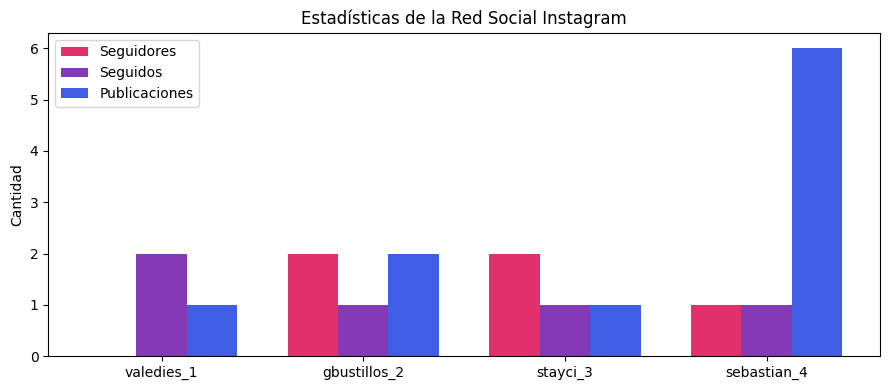

In [6]:
nombres = [u.obtener_nombre_usuario() for u in usuarios]
seguidores = [u.cantidad_seguidores() for u in usuarios]
seguidos = [u.cantidad_seguidos() for u in usuarios]
publicaciones = [u.cantidad_publicaciones() for u in usuarios]

x = range(len(usuarios))
plt.figure(figsize=(9, 4))
plt.bar([i - 0.25 for i in x], seguidores, 0.25, label="Seguidores", color="#E1306C")
plt.bar(x, seguidos, 0.25, label="Seguidos", color="#833AB4")
plt.bar([i + 0.25 for i in x], publicaciones, 0.25, label="Publicaciones", color="#405DE6")

plt.xticks(list(x), nombres)
plt.ylabel("Cantidad")
plt.title("Estadísticas de la Red Social Instagram")
plt.legend()
plt.tight_layout()
plt.show()

## Resultado

Se demostraron las funciones de seguimiento, historias, publicaciones y beneficios VIP utilizando solamente los cuatro perfiles registrados en el sistema. La gráfica muestra los contadores al finalizar estas pruebas; son **datos de esta ejecución**, no datos permanentes del programa.

In [7]:
print("RESULTADO FINAL: pruebas ejecutadas correctamente.")

RESULTADO FINAL: pruebas ejecutadas correctamente.
